### Problem 10 : Variational Quantum Classifier (VQC)

Everything we have built so far has been **fixed**. The circuits in Problems 1-9 had no knobs to
turn : we chose the gates, ran the circuit, and read the answer. Even the QSVM only used the
quantum computer as a fancy distance calculator - the actual *learning* happened in the classical
SVM.

A **Variational Quantum Classifier** is the first model in this repo that genuinely **trains**.
It is the quantum version of a neural network :

| Neural network | Variational quantum circuit |
|---|---|
| input layer | feature encoding (angle encoding) |
| hidden layers with weights | parameterised rotation gates + entanglers |
| forward pass | run the circuit, measure an observable |
| loss function | squared error between measurement and label |
| backpropagation | **parameter-shift rule** (gradients of a quantum circuit) |
| gradient descent | Adam / SGD, done classically |

This pattern - a quantum circuit whose parameters are tuned by a classical optimizer - is called a
**hybrid quantum-classical model**, and it is the single most important architecture in near-term
Quantum AI.

**TASK :** Train a variational circuit to separate the two interleaving half-moons of the classic
`make_moons` dataset.

#### The three pieces of a VQC

**1. The feature map (fixed).** Encodes the classical point x into a quantum state, exactly like
Problem 6. We reuse angle encoding : one RY rotation per feature.

**2. The ansatz (trainable).** A stack of parameterised rotations and CNOTs. We use PennyLane's
`StronglyEntanglingLayers`, which for each layer applies three rotation angles to every qubit and
then a ring of CNOTs. The word *ansatz* just means "the shape of circuit we guessed would work".

**3. The measurement.** We measure ⟨Z⟩ on qubit 0. This returns a number in [−1, +1], which is
perfect for labels of −1 and +1 : we predict `sign(⟨Z⟩ + bias)`.

#### How do you differentiate a quantum circuit ?

You cannot backpropagate through a quantum computer - there are no intermediate values to store,
and measuring would destroy the state. Instead, quantum ML uses the **parameter-shift rule** :

**∂f/∂θ = [ f(θ + π/2) − f(θ − π/2) ] / 2**

That is, to get the *exact* gradient with respect to one angle, you run the circuit twice more with
that angle shifted. It is not finite differences - it is exact - but it does mean a circuit with
P parameters needs 2P circuit evaluations per gradient step. PennyLane applies this rule for us
automatically when we call `opt.step`.

In [1]:
import pennylane as qml
from pennylane import numpy as np      # PennyLane's wrapped NumPy - it tracks gradients

from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt

> ⚠️ Note the import : `from pennylane import numpy as np`, **not** plain NumPy. PennyLane ships a
> thin wrapper around NumPy that records which arrays are trainable so it can differentiate through
> them. If you use plain NumPy here, `opt.step` will silently fail to find any parameters to train.

In [2]:
# Step 1: Generate the dataset
X, y = make_moons(n_samples=200, noise=0.15, random_state=42)

X = StandardScaler().fit_transform(X)   # centre and scale - rotation angles like small numbers
y = 2 * y - 1                           # relabel {0, 1} as {-1, +1} to match the range of <Z>

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Mark the data as NON-trainable so the optimizer only ever touches the weights
X_train = np.array(X_train, requires_grad=False)
y_train = np.array(y_train, requires_grad=False)

print("Training points:", X_train.shape, " Test points:", X_test.shape)

Training points: (140, 2)  Test points: (60, 2)


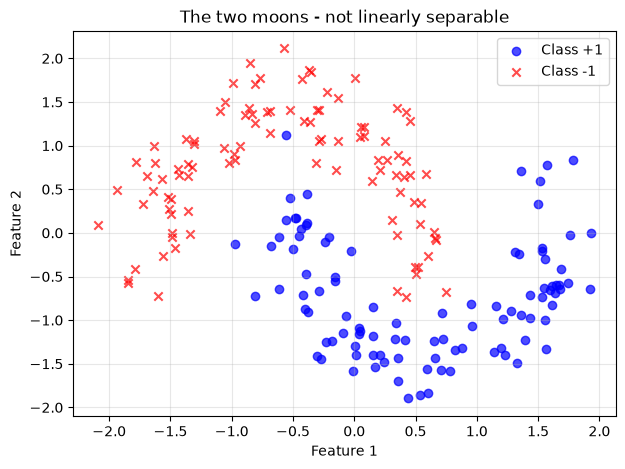

In [3]:
plt.figure(figsize=(7, 5))
plt.scatter(X[y == 1][:, 0], X[y == 1][:, 1], c='b', marker='o', label='Class +1', alpha=0.7)
plt.scatter(X[y == -1][:, 0], X[y == -1][:, 1], c='r', marker='x', label='Class -1', alpha=0.7)
plt.title("The two moons - not linearly separable")
plt.xlabel("Feature 1"); plt.ylabel("Feature 2")
plt.legend(); plt.grid(alpha=0.3); plt.show()

In [4]:
# Step 2: Build the variational circuit
n_qubits = 2
n_layers = 4

dev = qml.device("default.qubit", wires=n_qubits)


@qml.qnode(dev)
def circuit(weights, x):
    # (1) feature map - fixed, no trainable parameters
    qml.AngleEmbedding(x, wires=range(n_qubits), rotation='Y')

    # (2) ansatz - this is what we train
    qml.StronglyEntanglingLayers(weights, wires=range(n_qubits))

    # (3) measurement - a single number in [-1, +1]
    return qml.expval(qml.PauliZ(0))

In [5]:
# Have a look at what we actually built
weights_shape = qml.StronglyEntanglingLayers.shape(n_layers=n_layers, n_wires=n_qubits)
print("Weights shape (layers, qubits, rotations):", weights_shape)
print("Total trainable parameters:", int(np.prod(weights_shape)) + 1, "(+1 for the bias)")
print()

dummy = np.random.normal(0, 0.1, weights_shape)
print(qml.draw(circuit)(dummy, X_train[0]))

Weights shape (layers, qubits, rotations): (4, 2, 3)
Total trainable parameters: 25 (+1 for the bias)

0: ─╭AngleEmbedding(M0)─╭StronglyEntanglingLayers(M1)─┤  <Z>
1: ─╰AngleEmbedding(M0)─╰StronglyEntanglingLayers(M1)─┤     

M0 = 
[-0.88787167  1.35507279]
M1 = 
[[[ 0.15288101  0.16108769 -0.12624002]
  [ 0.1789788   0.14284088  0.05784373]]

 [[-0.01879157 -0.06625125 -0.14916561]
  [ 0.08408753  0.01851701  0.17119409]]

 [[-0.14827533  0.05206358 -0.01441788]
  [-0.04826836 -0.10566532  0.15836532]]

 [[ 0.02101127  0.06732786 -0.13353189]
  [ 0.18439362  0.01066509 -0.11991913]]]


In [6]:
# Step 3: Model, loss and accuracy
def model(weights, bias, X):
    """Run the circuit on every point and add the classical bias."""
    return np.array([circuit(weights, x) for x in X]) + bias


def cost(weights, bias, X, y):
    """Mean squared error between the circuit output and the +/-1 labels."""
    return np.mean((model(weights, bias, X) - y) ** 2)


def accuracy(weights, bias, X, y):
    predictions = np.sign(model(weights, bias, X))
    return np.mean(predictions == y)

#### Why squared error and not cross-entropy ?

Because our circuit outputs an *expectation value* in [−1, +1], not a probability. Squared error
against ±1 labels is the natural fit and is what most VQC papers use. You can absolutely build a
probabilistic version instead - measure `qml.probs` and use cross-entropy - and that is exactly
what Qiskit's `VQC` class does in Problem 11.

In [7]:
# Step 4: Train
np.random.seed(0)
weights = np.random.normal(0, 0.1, weights_shape, requires_grad=True)
bias = np.array(0.0, requires_grad=True)

opt = qml.AdamOptimizer(stepsize=0.15)
batch_size = 25
n_steps = 80

history = []
for step in range(n_steps):
    # mini-batch, exactly like classical SGD
    batch = np.random.randint(0, len(X_train), batch_size)
    weights, bias, _, _ = opt.step(cost, weights, bias, X_train[batch], y_train[batch])

    if (step + 1) % 10 == 0:
        c = cost(weights, bias, X_train, y_train)
        a = accuracy(weights, bias, X_train, y_train)
        history.append((step + 1, float(c), float(a)))
        print(f"Step {step + 1:3d} | loss {c:.4f} | train accuracy {a:.3f}")

Step  10 | loss 0.4390 | train accuracy 0.850


Step  20 | loss 0.5621 | train accuracy 0.821


Step  30 | loss 0.4566 | train accuracy 0.829


Step  40 | loss 0.4683 | train accuracy 0.829


Step  50 | loss 0.4299 | train accuracy 0.821


Step  60 | loss 0.4740 | train accuracy 0.821


Step  70 | loss 0.4320 | train accuracy 0.821


Step  80 | loss 0.4625 | train accuracy 0.829


In [8]:
# Step 5: Evaluate
train_acc = accuracy(weights, bias, X_train, y_train)
test_acc = accuracy(weights, bias, X_test, y_test)

print(f"Final training accuracy: {train_acc:.3f}")
print(f"Final test accuracy    : {test_acc:.3f}")

Final training accuracy: 0.829
Final test accuracy    : 0.850


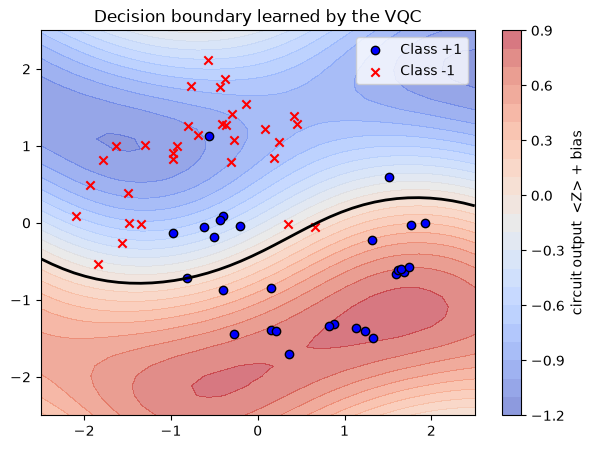

In [9]:
# Plot the decision boundary the circuit learned
xx, yy = np.meshgrid(np.linspace(-2.5, 2.5, 40), np.linspace(-2.5, 2.5, 40))
grid = np.c_[xx.ravel(), yy.ravel()]
zz = model(weights, bias, grid).reshape(xx.shape)

plt.figure(figsize=(7, 5))
plt.contourf(xx, yy, zz, levels=20, cmap='coolwarm', alpha=0.6)
plt.colorbar(label='circuit output  <Z> + bias')
plt.contour(xx, yy, zz, levels=[0], colors='k', linewidths=2)   # the decision boundary
plt.scatter(X_test[y_test == 1][:, 0], X_test[y_test == 1][:, 1], c='b', marker='o', edgecolor='k', label='Class +1')
plt.scatter(X_test[y_test == -1][:, 0], X_test[y_test == -1][:, 1], c='r', marker='x', label='Class -1')
plt.title("Decision boundary learned by the VQC")
plt.legend(); plt.show()

#### OUTCOME :

- The loss drops and the accuracy climbs - the quantum circuit really is learning.
- We land somewhere around **85%** on the test set, and then it stalls.

**Why does it stall ?** Look at the decision boundary : it is smooth and gentle, while the moons
need a curved, wrapping boundary. Our feature map encodes each point **exactly once**, right at the
start of the circuit. Everything after that is a fixed rotation of the same encoded state, so the
family of functions this circuit can express is quite limited - roughly a low-order trigonometric
function of x.

Adding more layers does *not* fix this, and Problem 12 will show you a nastier reason why simply
piling on layers is a bad idea. The real fix - feeding the data into the circuit **again and again**
- is Problem 13, where a **single qubit** will beat this two-qubit model.

#### Key Takeaways :
- A VQC = fixed feature map + trainable ansatz + measurement, optimized classically.
- Gradients come from the **parameter-shift rule**, not backpropagation.
- Use `pennylane.numpy` and mark your data `requires_grad=False`.
- **Expressivity is set by the feature map**, not by how many trainable layers you stack on top.

#### TASK :
1. Set `n_layers = 1` and re-train. How much worse is it? Now try `n_layers = 8` - is it better,
   or just slower?
2. Swap the measurement to `qml.expval(qml.PauliZ(0) @ qml.PauliZ(1))` (the parity of both qubits).
   Does reading out both qubits help?
3. Replace `AngleEmbedding(..., rotation='Y')` with `rotation='X'`. Explain why the accuracy
   collapses. *(Hint : what does RX do to the ∣0⟩ state, and what does ⟨Z⟩ measure?)*